First 5 rows:
   RowNumber  CustomerId   Surname  CreditScore Geography  Gender  Age  \
0          1    15634602  Hargrave          619    France  Female   42   
1          2    15647311      Hill          608     Spain  Female   41   
2          3    15619304      Onio          502    France  Female   42   
3          4    15701354      Boni          699    France  Female   39   
4          5    15737888  Mitchell          850     Spain  Female   43   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0       2       0.00              1          1               1   
1       1   83807.86              1          0               1   
2       8  159660.80              3          1               0   
3       1       0.00              2          0               0   
4       2  125510.82              1          1               1   

   EstimatedSalary  Exited  
0        101348.88       1  
1        112542.58       0  
2        113931.57       1  
3         93826.63       0  

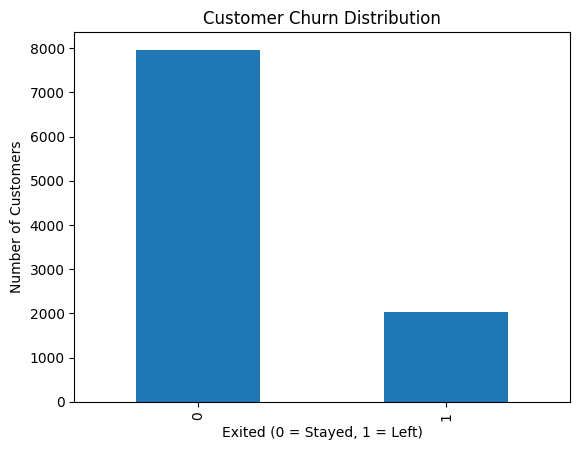


Actual vs Predicted:
 Actual  Predicted
      0          0
      0          0
      0          0
      0          0
      0          0
      0          0
      0          0
      0          1
      0          0
      0          0

Accuracy: 0.84
Precision: 0.89
Recall: 0.25
F1-score: 0.39


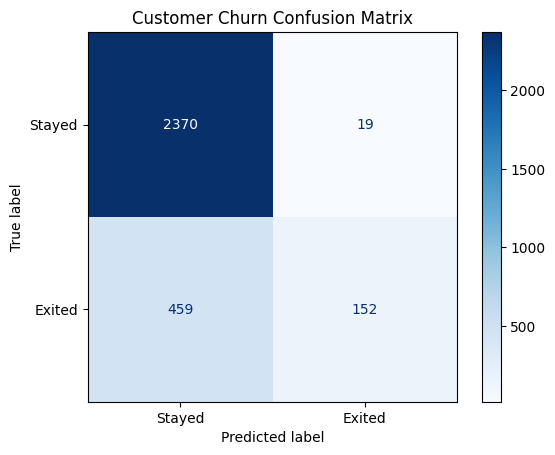

In [2]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)

# 1. Load dataset
df = pd.read_csv("/content/Churn_Modelling - Churn_Modelling.csv")

print("First 5 rows:")
print(df.head())

# 2. Perform EDA
print("\nMissing values:")
print(df.isnull().sum())

print("\nChurn distribution:")
print(df["Exited"].value_counts())

df["Exited"].value_counts().plot(kind="bar")
plt.title("Customer Churn Distribution")
plt.xlabel("Exited (0 = Stayed, 1 = Left)")
plt.ylabel("Number of Customers")
plt.show()

# 3. Handle missing values
for col in df.select_dtypes(include="number").columns:
    df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].fillna(df[col].mode()[0])

# Remove unnecessary columns
df = df.drop(["RowNumber", "CustomerId", "Surname"], axis=1)

# Convert categorical columns into numeric columns
df = pd.get_dummies(df, columns=["Geography", "Gender"], dtype=int)

# Prepare features and target
X = df.drop("Exited", axis=1)
y = df["Exited"]

# 4. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# 5. Train Decision Tree
model = DecisionTreeClassifier(
    criterion="gini", max_depth=3, random_state=42
)
model.fit(X_train, y_train)

# 6. Predict churn
y_pred = model.predict(X_test)

print("\nActual vs Predicted:")
print(pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
}).head(10).to_string(index=False))

# 7. Evaluate model
print("\nAccuracy:", round(accuracy_score(y_test, y_pred), 2))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 2))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 2))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 2))

# 8. Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Exited"]
)
disp.plot(cmap="Blues")
plt.title("Customer Churn Confusion Matrix")
plt.show()


First 5 rows:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies       

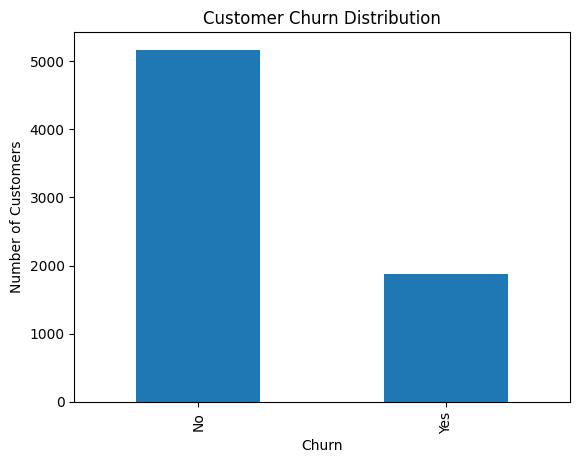


Actual vs Predicted:
 Actual  Predicted
      1          0
      0          0
      1          0
      0          0
      0          0
      0          0
      0          0
      1          0
      1          0
      0          0

Accuracy: 0.78
Precision: 0.7
Recall: 0.31
F1-score: 0.43


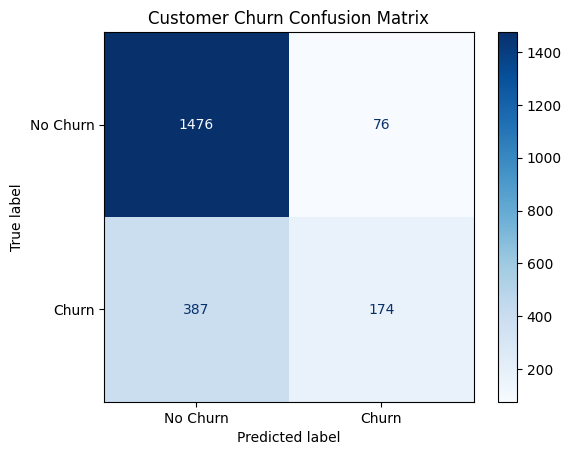

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)

# 1. Load dataset
df = pd.read_csv("/content/WA_Fn-UseC_-Telco-Customer-Churn - WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("First 5 rows:")
print(df.head())

# 2. Perform EDA
print("\nMissing values:")
print(df.isnull().sum())

print("\nChurn distribution:")
print(df["Churn"].value_counts())

df["Churn"].value_counts().plot(kind="bar")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

# 3. Preprocess the data
df = df.drop("customerID", axis=1)

# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Handle missing values
df["TotalCharges"] = df["TotalCharges"].fillna(
    df["TotalCharges"].median()
)

# Convert categorical columns to numeric
df = pd.get_dummies(df, drop_first=True, dtype=int)

# Separate features and target
X = df.drop("Churn_Yes", axis=1)
y = df["Churn_Yes"]

# 4. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# 5. Train Decision Tree model
model = DecisionTreeClassifier(
    criterion="gini", max_depth=3, random_state=42
)

model.fit(X_train, y_train)

# 6. Make predictions
y_pred = model.predict(X_test)

print("\nActual vs Predicted:")
print(pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
}).head(10).to_string(index=False))

# 7. Evaluate the model
print("\nAccuracy:", round(accuracy_score(y_test, y_pred), 2))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 2))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 2))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 2))

# 8. Display confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot(cmap="Blues")
plt.title("Customer Churn Confusion Matrix")
plt.show()